#  pénalisation ou contrainte explicite ?

On compare

$$\text{(P)}\quad \min_\theta F_{train}(\theta) + \frac{\lambda}{2}\|\theta\|_2^2
\qquad\text{et}\qquad
\text{(C)}\quad \min_\theta F_{train}(\theta)\ \ \text{s.c.}\ \ \|\theta\|_2 \le R,$$

avec la convention du sujet ($\|\theta\|_2^2 = \sum_\ell \|W^{(\ell)}\|_F^2$, biais exclus).

**Lien théorique.** Pour (C), le lagrangien s'écrit $F_{train}(\theta) + \frac{\mu}{2}(\|\theta\|_2^2 - R^2)$. En un point KKT où la contrainte est active, $\nabla F_{train}(\theta^\star) + \mu\,\theta^\star = 0$ avec $\mu \ge 0$. C'est exactement la condition de stationnarité de (P) avec $\lambda = \mu$. En convexe, les deux formulations ont donc les mêmes solutions pour le bon couple $(\lambda, R)$. Ici le problème n'est pas convexe et l'entraînement est stochastique : on vérifie expérimentalement jusqu'où cette correspondance tient.

**Construction des couples $(\lambda, R)$ (fixée avant les expériences)**

1. On entraîne (P) pour $\lambda \in \{10^{-5}, 10^{-4}, 10^{-3}, 10^{-2}\}$, 500 époques, batch 32, seeds 0 à 4.
2. Pour chaque seed, on prend $R = \|\theta^\star_\lambda\|_2$, la norme finale du modèle pénalisé.
3. On entraîne (C) avec ce $R$, la même seed et **le même optimiseur**, suivi de la projection.

Les deux modèles d'un couple ont ainsi la même initialisation, le même ordre de mini-batchs et la même norme finale. Seule la façon de contrôler la norme change. $\lambda = 10^{-1}$ n'est pas retenu, car il sous-apprend fortement en D.

**Deux optimiseurs**

- **Comparaison principale : SGD (lr = 0.1).** (C) est alors exactement le gradient projeté du sujet.
- **Comparaison secondaire : Adam (lr = 0.003)**, l'optimiseur de D, avec « Adam projeté » pour (C). La section 5 montre que cette variante ne résout pas correctement (C) et explique pourquoi.

**Jeu de test.** Le sujet demande l'accuracy test. Aucun choix n'est fait à partir du test : les couples sont fixés avant, et le test est évalué une seule fois, à la fin, pour tous les modèles.

In [13]:
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.append('..')
from src.data import load_data
from src.model import MLP
from src.optimizers import SGD, Adam
from src.train import train
from src.losses import bce
from src.constraints import weights_norm, is_active, kkt_multiplier, ProjectedOptimizer

data = load_data(seed=42)
SEEDS = [0, 1, 2, 3, 4]
EPOCHS, BATCH, LR = 500, 32, 0.003
LAMBDAS = [1e-5, 1e-4, 1e-3, 1e-2]
OPTS = {'SGD': lambda: SGD(lr=0.1), 'Adam': lambda: Adam(lr=LR)}
METHODS = ['pénalité', 'contrainte']

def fit(*args, **kwargs):
    # train(...) puis conversion de l'historique en tableaux numpy
    h = train(*args, **kwargs)
    return {k: (np.asarray(v) if k != 'meta' else v) for k, v in h.items()}

def epoch_axis(h):
    # 0..EPOCHS si train.py enregistre l'état initial, sinon 1..EPOCHS
    n = len(h['loss_val'])
    return np.arange(n) if n == EPOCHS + 1 else np.arange(1, n + 1)

def scores(model, X, y):
    # loss = BCE seule (sans pénalité), pour comparer (P) et (C) sur la même mesure
    model.eval()
    p = model.forward(X)
    return bce(p, y), float(np.mean((p.ravel() > 0.5) == (np.ravel(y) > 0.5))), p.ravel()

## 1. Entraînement des couples $(\lambda, R)$

In [14]:
runs = {}       # (optimiseur, méthode, lambda, seed) -> dict(historique, modèle, R, mu, ...)
for opt_name, make_opt in OPTS.items():
    for lam in LAMBDAS:
        for s in SEEDS:
            m_p = MLP(seed=s)
            h_p = fit(m_p, make_opt(), data, epochs=EPOCHS, batch_size=BATCH, seed=s, l2=lam)
            R = weights_norm(m_p)

            m_c = MLP(seed=s)
            opt = ProjectedOptimizer(make_opt(), m_c, R)
            h_c = fit(m_c, opt, data, epochs=EPOCHS, batch_size=BATCH, seed=s)
            pre = np.array(opt.pre_norms)

            for name, m, h in [('pénalité', m_p, h_p), ('contrainte', m_c, h_c)]:
                mu, cos = kkt_multiplier(m, data['X_train'], data['y_train'])
                runs[opt_name, name, lam, s] = dict(
                    h=h, model=m, R=R, norm=weights_norm(m), mu=mu, cos=cos,
                    proj_rate=opt.projection_rate() if name == 'contrainte' else None,
                    first_proj=(int(np.argmax(pre > R)) * EPOCHS // len(pre) + 1)
                               if name == 'contrainte' and opt.projection_rate() > 0 else None)
print('Entraînements terminés :', len(runs))

Entraînements terminés : 80


## 2. Comparaison principale (SGD) : train et validation

Valeurs à la dernière époque, moyenne ± écart-type sur 5 seeds. Les loss sont des BCE **sans** le terme de pénalité, pour que (P) et (C) soient mesurés de la même façon.

- **μ estimé** : multiplicateur estimé en fin d'entraînement, $\mu = -\langle\nabla_W F, W\rangle/\|W\|^2$ (partie E). Si la correspondance KKT était exacte, on aurait $\mu \approx \lambda$ pour les deux méthodes.
- **cos** : $\cos(-\nabla_W F, W)$. Il vaut 1 en un point KKT exact, donc il indique si l'estimation de μ est fiable.

In [15]:
def ms(v, d=4):
    return f"{np.mean(v):.{d}f} ± {np.std(v, ddof=1):.{d}f}"

rows, raw = [], []
for opt_name in OPTS:
    for lam in LAMBDAS:
        for name in METHODS:
            rs = [runs[opt_name, name, lam, s] for s in SEEDS]
            sc_tr = [scores(r['model'], data['X_train'], data['y_train']) for r in rs]
            sc_va = [scores(r['model'], data['X_val'], data['y_val']) for r in rs]
            act = [is_active(r['norm'], r['R']) for r in rs]
            rows.append({'optimiseur': opt_name, 'λ': f'{lam:g}', 'méthode': name, 'R moyen': f"{np.mean([r['R'] for r in rs]):.2f}",
                         'loss train': ms([x[0] for x in sc_tr]), 'loss val': ms([x[0] for x in sc_va]),
                         'acc val': ms([x[1] for x in sc_va], 3), '‖θ‖': ms([r['norm'] for r in rs], 2),
                         'contrainte active': f'{sum(act)}/5' if name == 'contrainte' else '–',
                         'pas projetés': f"{np.mean([r['proj_rate'] for r in rs]):.0%}" if name == 'contrainte' else '–',
                         'μ estimé': ms([r['mu'] for r in rs], 5), 'cos': f"{np.mean([r['cos'] for r in rs]):.2f}"})
            for s, r, tr, va in zip(SEEDS, rs, sc_tr, sc_va):
                raw.append(dict(optimiseur=opt_name, lam=lam, methode=name, seed=s, R=r['R'], norm=r['norm'],
                                loss_train=tr[0], loss_val=va[0], acc_val=va[1], mu=r['mu'], cos=r['cos'],
                                proj_rate=r['proj_rate'], first_proj=r['first_proj']))
df_raw = pd.DataFrame(raw)
table_F = pd.DataFrame(rows).set_index(['optimiseur', 'λ', 'méthode'])
table_F.loc['SGD']

R moyen       loss train         loss val        acc val  \
λ      méthode                                                               
1e-05  pénalité      9.97  0.0781 ± 0.0066  0.0953 ± 0.0032  0.965 ± 0.004   
       contrainte    9.97  0.0781 ± 0.0067  0.0958 ± 0.0028  0.965 ± 0.004   
0.0001 pénalité      9.44  0.0799 ± 0.0081  0.0960 ± 0.0067  0.965 ± 0.007   
       contrainte    9.44  0.0781 ± 0.0067  0.0958 ± 0.0028  0.965 ± 0.004   
0.001  pénalité      6.92  0.0835 ± 0.0030  0.0897 ± 0.0054  0.967 ± 0.002   
       contrainte    6.92  0.0781 ± 0.0067  0.0958 ± 0.0028  0.965 ± 0.004   
0.01   pénalité      4.86  0.1258 ± 0.0068  0.1271 ± 0.0062  0.955 ± 0.004   
       contrainte    4.86  0.0781 ± 0.0067  0.0958 ± 0.0028  0.965 ± 0.004   

                            ‖θ‖ contrainte active pas projetés  \
λ      méthode                                                   
1e-05  pénalité     9.97 ± 0.53                 –            –   
       contrainte  10.03 ± 0.54               0/5           6%   
0.0001 pénalité     9.44 ± 0.45                 –            –   
       contrainte  10.03 ± 0.54               0/5          52%   
0.001  pénalité     6.92 ± 0.21                 –            –   
       contrainte  10.03 ± 0.54               0/5          99%   
0.01   pénalité     4.86 ± 0.02                 –            –   
       contrainte  10.03 ± 0.54               0/5         100%   

                            μ estimé    cos  
λ      méthode                               
1e-05  pénalité    0.00036 ± 0.00049  -0.01  
       contrainte  0.00033 ± 0.00051  -0.01  
0.0001 pénalité    0.00051 ± 0.00064  -0.00  
       contrainte  0.00033 ± 0.00051  -0.01  
0.001  pénalité    0.00141 ± 0.00098   0.11  
       contrainte  0.00033 ± 0.00051  -0.01  
0.01   pénalité    0.01333 ± 0.00617   0.49  
       contrainte  0.00033 ± 0.00051  -0.01

In [16]:
# Les deux solutions d'un couple sont-elles les mêmes ? (même seed, même norme)
rows = []
for opt_name in OPTS:
    for lam in LAMBDAS:
        d_rel, agree = [], []
        for s in SEEDS:
            mp, mc = runs[opt_name, 'pénalité', lam, s]['model'], runs[opt_name, 'contrainte', lam, s]['model']
            tp, tc = mp.get_params(), mc.get_params()
            d_rel.append(np.linalg.norm(tp - tc) / np.linalg.norm(tp))
            agree.append(np.mean((scores(mp, data['X_val'], data['y_val'])[2] > 0.5) ==
                                 (scores(mc, data['X_val'], data['y_val'])[2] > 0.5)))
        rows.append({'optimiseur': opt_name, 'λ': f'{lam:g}', 'distance relative ‖θ_P − θ_C‖ / ‖θ_P‖': ms(d_rel, 3),
                     'prédictions val identiques': ms(agree, 3),
                     'époque où la contrainte commence à agir': ms([runs[opt_name, 'contrainte', lam, s]['first_proj'] or np.nan for s in SEEDS], 0)})
pd.DataFrame(rows).set_index(['optimiseur', 'λ'])

distance relative ‖θ_P − θ_C‖ / ‖θ_P‖  \
optimiseur λ                                              
SGD        1e-05                          0.015 ± 0.008   
           0.0001                         0.096 ± 0.031   
           0.001                          0.673 ± 0.070   
           0.01                           1.350 ± 0.149   
Adam       1e-05                          0.520 ± 0.144   
           0.0001                         0.919 ± 0.294   
           0.001                          1.708 ± 0.347   
           0.01                           2.459 ± 0.420   

                  prédictions val identiques  \
optimiseur λ                                   
SGD        1e-05               1.000 ± 0.000   
           0.0001              0.998 ± 0.002   
           0.001               0.989 ± 0.005   
           0.01                0.970 ± 0.012   
Adam       1e-05               0.997 ± 0.001   
           0.0001              0.995 ± 0.004   
           0.001               0.985 ± 0.008   
           0.01                0.957 ± 0.007   

                  époque où la contrainte commence à agir  
optimiseur λ                                               
SGD        1e-05                                 464 ± 14  
           0.0001                                230 ± 47  
           0.001                                    5 ± 4  
           0.01                                     1 ± 0  
Adam       1e-05                                 375 ± 51  
           0.0001                                 60 ± 11  
           0.001                                    2 ± 1  
           0.01                                     1 ± 0

## 3. Trajectoires (SGD) : norme, loss et stabilité

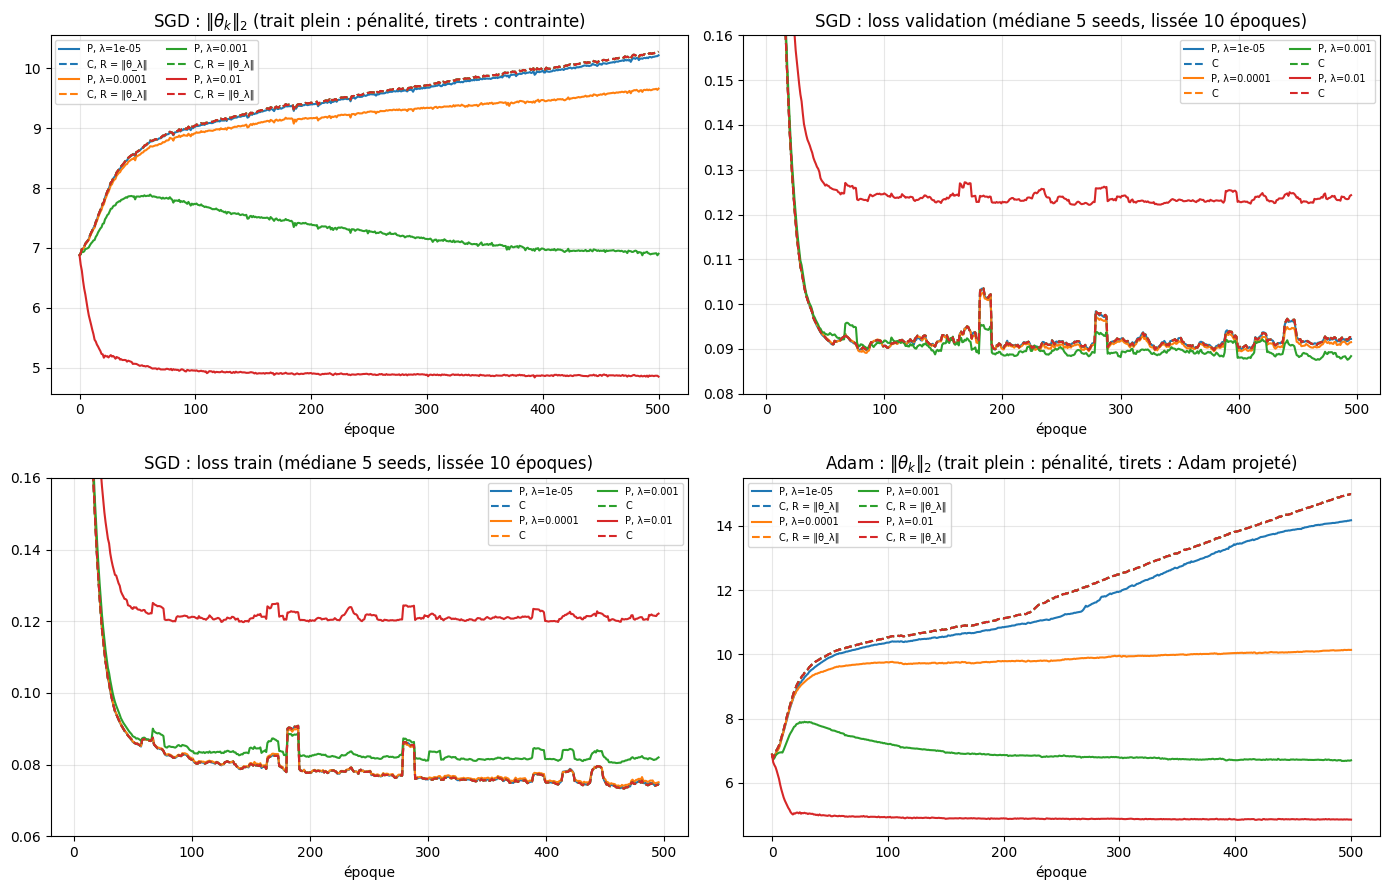

In [17]:
colors = dict(zip(LAMBDAS, ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']))
def curve(o, name, lam, k, smooth=1):
    # médiane sur les seeds (robuste aux pics de SGD), puis moyenne glissante sur `smooth` époques
    y = np.median([runs[o, name, lam, s]['h'][k] for s in SEEDS], axis=0)
    return np.convolve(y, np.ones(smooth) / smooth, mode='same') if smooth > 1 else y
ep = epoch_axis(runs['SGD', 'pénalité', LAMBDAS[0], 0]['h'])
cut = slice(5, -5)      # bords de la moyenne glissante

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
for lam in LAMBDAS:
    c = colors[lam]
    for a_, o in [(ax[0, 0], 'SGD'), (ax[1, 1], 'Adam')]:
        a_.plot(ep, curve(o, 'pénalité', lam, 'weight_norm'), color=c, label=f'P, λ={lam:g}')
        a_.plot(ep, curve(o, 'contrainte', lam, 'weight_norm'), color=c, ls='--', label='C, R = ‖θ_λ‖')
    ax[0, 1].plot(ep[cut], curve('SGD', 'pénalité', lam, 'loss_val', 10)[cut], color=c, label=f'P, λ={lam:g}')
    ax[0, 1].plot(ep[cut], curve('SGD', 'contrainte', lam, 'loss_val', 10)[cut], color=c, ls='--', label='C')
    ax[1, 0].plot(ep[cut], curve('SGD', 'pénalité', lam, 'loss_train', 10)[cut], color=c, label=f'P, λ={lam:g}')
    ax[1, 0].plot(ep[cut], curve('SGD', 'contrainte', lam, 'loss_train', 10)[cut], color=c, ls='--', label='C')
ax[0, 0].set(title=r'SGD : $\|\theta_k\|_2$ (trait plein : pénalité, tirets : contrainte)', xlabel='époque')
ax[0, 1].set(title='SGD : loss validation (médiane 5 seeds, lissée 10 époques)', xlabel='époque', ylim=(0.08, 0.16))
ax[1, 0].set(title='SGD : loss train (médiane 5 seeds, lissée 10 époques)', xlabel='époque', ylim=(0.06, 0.16))
ax[1, 1].set(title=r'Adam : $\|\theta_k\|_2$ (trait plein : pénalité, tirets : Adam projeté)', xlabel='époque')
for a_ in ax.flat:
    a_.grid(alpha=.3); a_.legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig('../results/F1_trajectories.png', dpi=150); plt.show()

**Mesures de stabilité.** Trois indicateurs, calculés sur les 100 dernières époques :

- **dispersion entre seeds** : écart-type, entre seeds, de la loss de validation finale ;
- **oscillation** : variation moyenne d'une époque à l'autre, $\text{moyenne}\,|F_{val}(\theta_{k+1}) - F_{val}(\theta_k)|$ ;
- **dérive** : variation de la loss de validation entre l'époque 400 et l'époque 500. Une valeur positive veut dire qu'elle remonte encore ;
- **pics** : nombre d'époques où la loss de validation dépasse 1.5 fois sa médiane (sauts brusques, fréquents avec SGD à lr = 0.1).

In [18]:
rows = []
for opt_name in OPTS:
    for lam in LAMBDAS:
        for name in METHODS:
            H = [runs[opt_name, name, lam, s]['h'] for s in SEEDS]
            rows.append({'optimiseur': opt_name, 'λ': f'{lam:g}', 'méthode': name,
                         'dispersion entre seeds (loss val finale)': np.std([h['loss_val'][-1] for h in H], ddof=1),
                         'oscillation (100 dernières époques)': np.mean([np.abs(np.diff(h['loss_val'][-101:])).mean() for h in H]),
                         'dérive val (époque 400 → 500)': np.mean([h['loss_val'][-1] - h['loss_val'][-101] for h in H]),
                         'pics de loss val (> 1.5 × médiane, 100 dernières)': np.mean([np.sum(h['loss_val'][-100:] > 1.5 * np.median(h['loss_val'][-100:])) for h in H])})
stab = pd.DataFrame(rows).set_index(['optimiseur', 'λ', 'méthode'])
stab.loc['SGD'].round(5)

dispersion entre seeds (loss val finale)  \
λ      méthode                                                
1e-05  pénalité                                     0.00318   
       contrainte                                   0.00276   
0.0001 pénalité                                     0.00670   
       contrainte                                   0.00276   
0.001  pénalité                                     0.00542   
       contrainte                                   0.00276   
0.01   pénalité                                     0.00623   
       contrainte                                   0.00276   

                   oscillation (100 dernières époques)  \
λ      méthode                                           
1e-05  pénalité                                0.01070   
       contrainte                              0.01072   
0.0001 pénalité                                0.01061   
       contrainte                              0.01072   
0.001  pénalité                                0.00886   
       contrainte                              0.01072   
0.01   pénalité                                0.00730   
       contrainte                              0.01072   

                   dérive val (époque 400 → 500)  \
λ      méthode                                     
1e-05  pénalité                          0.00235   
       contrainte                        0.00294   
0.0001 pénalité                          0.00370   
       contrainte                        0.00294   
0.001  pénalité                         -0.00304   
       contrainte                        0.00294   
0.01   pénalité                          0.00321   
       contrainte                        0.00294   

                   pics de loss val (> 1.5 × médiane, 100 dernières)  
λ      méthode                                                        
1e-05  pénalité                                                  2.2  
       contrainte                                                2.0  
0.0001 pénalité                                                  2.0  
       contrainte                                                2.0  
0.001  pénalité                                                  2.0  
       contrainte                                                2.0  
0.01   pénalité                                                  0.8  
       contrainte                                                2.0

## 4. Comparaison secondaire : Adam et « Adam projeté »

In [19]:
table_F.loc['Adam']

R moyen       loss train         loss val        acc val  \
λ      méthode                                                               
1e-05  pénalité     13.45  0.0678 ± 0.0028  0.0973 ± 0.0076  0.965 ± 0.004   
       contrainte   13.45  0.0678 ± 0.0033  0.1045 ± 0.0095  0.964 ± 0.004   
0.0001 pénalité      9.86  0.0721 ± 0.0014  0.0903 ± 0.0079  0.966 ± 0.004   
       contrainte    9.86  0.0678 ± 0.0033  0.1045 ± 0.0095  0.964 ± 0.004   
0.001  pénalité      6.77  0.0800 ± 0.0007  0.0857 ± 0.0030  0.967 ± 0.003   
       contrainte    6.77  0.0678 ± 0.0033  0.1045 ± 0.0095  0.964 ± 0.004   
0.01   pénalité      4.86  0.1201 ± 0.0012  0.1226 ± 0.0003  0.957 ± 0.005   
       contrainte    4.86  0.0678 ± 0.0033  0.1045 ± 0.0095  0.964 ± 0.004   

                            ‖θ‖ contrainte active pas projetés  \
λ      méthode                                                   
1e-05  pénalité    13.45 ± 1.45                 –            –   
       contrainte  15.26 ± 2.34               0/5          25%   
0.0001 pénalité     9.86 ± 0.49                 –            –   
       contrainte  15.26 ± 2.34               0/5          88%   
0.001  pénalité     6.77 ± 0.12                 –            –   
       contrainte  15.26 ± 2.34               0/5         100%   
0.01   pénalité     4.86 ± 0.01                 –            –   
       contrainte  15.26 ± 2.34               0/5         100%   

                            μ estimé   cos  
λ      méthode                              
1e-05  pénalité    0.00017 ± 0.00016  0.03  
       contrainte  0.00014 ± 0.00013  0.02  
0.0001 pénalité    0.00035 ± 0.00033  0.07  
       contrainte  0.00014 ± 0.00013  0.02  
0.001  pénalité    0.00123 ± 0.00082  0.19  
       contrainte  0.00014 ± 0.00013  0.02  
0.01   pénalité    0.01066 ± 0.00128  0.73  
       contrainte  0.00014 ± 0.00013  0.02

**Constat.** Avec Adam, à norme égale, le modèle contraint est nettement moins bon que le modèle pénalisé dès que la contrainte agit tôt ($\lambda \ge 10^{-3}$). Or le modèle pénalisé $\theta_P$ a exactement la norme $R$ : c'est un point **admissible** de (C), avec une loss train plus basse. Le problème (C) n'est donc pas en cause, c'est l'algorithme qui le résout mal.

**Explication.** Adam fait le pas $\theta - \alpha D_k^{-1} \hat m_k$, où $D_k = \mathrm{diag}(\sqrt{\hat v_k} + \varepsilon)$ met chaque composante à l'échelle. Un point fixe de « Adam projeté » sur le bord vérifie

$$P_C\big(\theta - \alpha D^{-1}\nabla F(\theta)\big) = \theta \iff D^{-1}\nabla F(\theta) = -c\,\theta \ \ (c \ge 0),$$

alors qu'un point KKT de (C) vérifie $\nabla F(\theta) = -\mu\,\theta$. Ces deux conditions ne coïncident que si $D$ est proportionnelle à l'identité. La projection euclidienne n'est cohérente qu'avec un pas de gradient non mis à l'échelle. C'est pourquoi le sujet définit le gradient projeté avec $\theta - \alpha \nabla F$. Une version correcte avec Adam demanderait de projeter dans la métrique de $D$, ce qui sort du cadre du projet.

**Vérification.** On part du modèle pénalisé $\theta_P$, qui est admissible et bon, et on continue 100 époques avec chaque méthode projetée. Si la méthode respecte la géométrie de (C), elle ne doit pas dégrader la loss train.

In [20]:
rows = []
for s in SEEDS:
    lam = 1e-3
    r = runs['Adam', 'pénalité', lam, s]
    f0 = scores(r['model'], data['X_train'], data['y_train'])[0]
    row = {'seed': s, 'R': r['R'], 'loss train de θ_P (départ)': f0}
    for opt_name, make_opt in OPTS.items():
        m = MLP(seed=s); m.set_params(r['model'].get_params())
        fit(m, ProjectedOptimizer(make_opt(), m, r['R']), data, epochs=100, batch_size=BATCH, seed=s)
        row[f'après 100 époques, {opt_name} projeté'] = scores(m, data['X_train'], data['y_train'])[0]
    rows.append(row)
warm = pd.DataFrame(rows).set_index('seed')
warm.loc['moyenne'] = warm.mean()
warm.round(4)

,R,loss train de θ_P (départ),"après 100 époques, SGD projeté","après 100 époques, Adam projeté"
seed,,,,
0,6.7007,0.0805,0.0792,0.0777
1,6.6817,0.0796,0.0789,0.0765
2,6.6651,0.0800,0.0783,0.0767
3,6.9402,0.0791,0.0774,0.0739
4,6.8442,0.0808,0.0787,0.0774
moyenne,6.7664,0.0800,0.0785,0.0765


## 5. Évaluation sur le test (une seule fois)

Les couples et les modèles sont fixés. On évalue le test une seule fois, pour les 80 modèles, sans rien modifier ensuite. Comme dans D2, la cellule refuse de s'exécuter une deuxième fois dans la même session.

In [21]:
if globals().get('TEST_F_DONE', False):
    raise RuntimeError('Le test a déjà été évalué dans cette session. Redémarre le noyau avant de relancer.')

test_rows = []
for (opt_name, name, lam, s), r in runs.items():
    lt, at, _ = scores(r['model'], data['X_test'], data['y_test'])
    test_rows.append(dict(optimiseur=opt_name, lam=lam, methode=name, seed=s, loss_test=lt, acc_test=at))
TEST_F_DONE = True

df_test = pd.DataFrame(test_rows)
tab_test = df_test.groupby(['optimiseur', 'lam', 'methode'], sort=False).agg(acc_test=('acc_test', 'mean'), acc_test_std=('acc_test', 'std'),
                                                              loss_test=('loss_test', 'mean'), loss_test_std=('loss_test', 'std'))
print(f"Sur {len(data['y_test'])} points de test, un exemple = {1 / len(data['y_test']):.4f} d'accuracy")
tab_test.round(4)

RuntimeError: Le test a déjà été évalué dans cette session. Redémarre le noyau avant de relancer.

In [10]:
# Différences appariées par seed : contrainte − pénalité
rows = []
for opt_name in OPTS:
  for lam in LAMBDAS:
    sel = (df_test.optimiseur == opt_name) & (df_test.lam == lam)
    p = df_test[sel & (df_test.methode == 'pénalité')].set_index('seed')
    c = df_test[sel & (df_test.methode == 'contrainte')].set_index('seed')
    d_acc, d_loss = c.acc_test - p.acc_test, c.loss_test - p.loss_test
    rows.append({'optimiseur': opt_name, 'λ': f'{lam:g}', 'Δ acc test (C − P)': ms(d_acc, 4), 'Δ loss test (C − P)': ms(d_loss, 4),
                 'écart moyen en nombre d\'exemples': f'{np.mean(np.abs(d_acc)) * len(data["y_test"]):.1f}'})
pd.DataFrame(rows).set_index(['optimiseur', 'λ'])

Δ acc test (C − P) Δ loss test (C − P)  \
optimiseur λ                                               
SGD        1e-05    -0.0007 ± 0.0015     0.0003 ± 0.0004   
           0.0001    0.0007 ± 0.0028    -0.0011 ± 0.0052   
           0.001    -0.0013 ± 0.0056     0.0026 ± 0.0049   
           0.01      0.0053 ± 0.0077    -0.0349 ± 0.0105   
Adam       1e-05    -0.0007 ± 0.0015     0.0051 ± 0.0065   
           0.0001   -0.0033 ± 0.0041     0.0076 ± 0.0099   
           0.001    -0.0040 ± 0.0104     0.0041 ± 0.0123   
           0.01      0.0060 ± 0.0072    -0.0306 ± 0.0137   

                  écart moyen en nombre d'exemples  
optimiseur λ                                        
SGD        1e-05                               0.2  
           0.0001                              0.6  
           0.001                               1.2  
           0.01                                2.4  
Adam       1e-05                               0.2  
           0.0001                              1.0  
           0.001                               2.8  
           0.01                                1.8

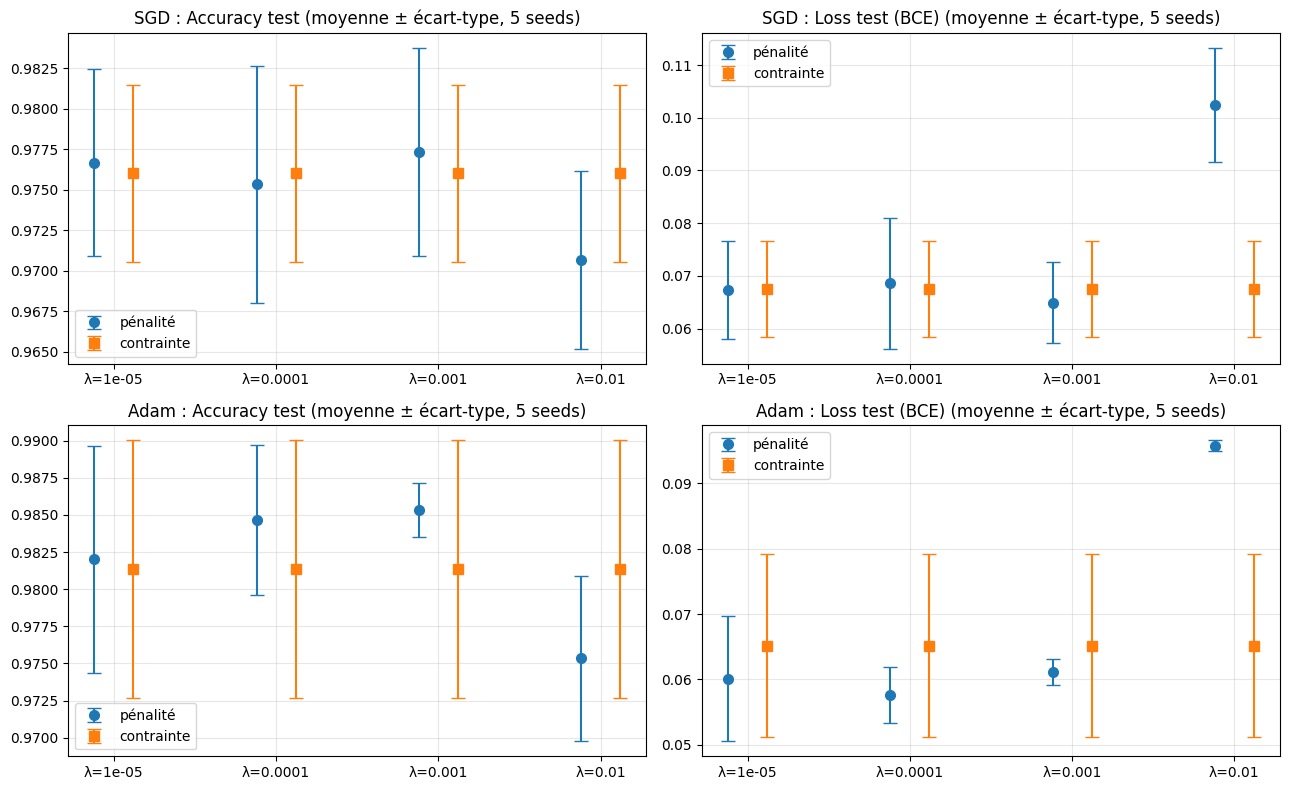

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
xs = np.arange(len(LAMBDAS))
for i, opt_name in enumerate(OPTS):
    for name, off, mk in [('pénalité', -0.12, 'o'), ('contrainte', 0.12, 's')]:
        t = tab_test.loc[opt_name].xs(name, level='methode')
        for a, m in [(ax[i, 0], 'acc_test'), (ax[i, 1], 'loss_test')]:
            a.errorbar(xs + off, t[m].values, yerr=t[m + '_std'].values, fmt=mk, capsize=5, ms=7, label=name)
    for a, t in [(ax[i, 0], 'Accuracy test'), (ax[i, 1], 'Loss test (BCE)')]:
        a.set_xticks(xs); a.set_xticklabels([f'λ={l:g}' for l in LAMBDAS])
        a.set_title(f'{opt_name} : {t} (moyenne ± écart-type, 5 seeds)'); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig('../results/F1_test.png', dpi=150); plt.show()

table_F.to_csv('../results/F1_table.csv'); stab.to_csv('../results/F1_stability.csv')
df_raw.merge(df_test, on=['optimiseur', 'lam', 'methode', 'seed']).to_csv('../results/F1_runs.csv', index=False)

## 6. J4 : contrainte active et inactive

Dans toutes les expériences de F, la contrainte est active : R est choisi égal à la norme du modèle pénalisé, qui est plus petite que celle du modèle non contraint. Le cas inactif est montré en partie E (notebook 07) : pour $R = 1.5\,R_0$ et $R = 2\,R_0$, la projection n'agit jamais et la trajectoire est identique, bit à bit, à l'entraînement non contraint. La cellule ci-dessous le refait avec le gradient projeté strict (SGD), pour que J4 soit complet dans ce notebook. $R_0$ est la norme finale de SGD sans contrainte.

In [12]:
rows = []
for s in SEEDS:
    m_ref = MLP(seed=s); h_ref = fit(m_ref, SGD(lr=0.1), data, epochs=EPOCHS, batch_size=BATCH, seed=s)
    R0 = weights_norm(m_ref)
    for c in [0.5, 2.0]:
        m = MLP(seed=s); opt = ProjectedOptimizer(SGD(lr=0.1), m, c * R0)
        h = fit(m, opt, data, epochs=EPOCHS, batch_size=BATCH, seed=s)
        rows.append({'seed': s, 'R': f'{c} R0', '‖θ*‖': weights_norm(m), 'R valeur': c * R0,
                     'r_feas': max(0.0, weights_norm(m) - c * R0), 'active': is_active(weights_norm(m), c * R0),
                     'pas projetés': opt.projection_rate(),
                     'identique au non contraint': bool(np.array_equal(h['loss_val'], h_ref['loss_val']))})
pd.DataFrame(rows).groupby('R').agg(norme=('‖θ*‖', 'mean'), R=('R valeur', 'mean'), r_feas_max=('r_feas', 'max'),
                                    actives=('active', 'sum'), pas_projetes=('pas projetés', 'mean'),
                                    identiques=('identique au non contraint', 'sum')).round(4)

,norme,R,r_feas_max,actives,pas_projetes,identiques
R,,,,,,
0.5 R0,10.031,5.0155,5.1845,0,1.0,5
2.0 R0,10.031,20.0621,0.0000,0,0.0,5


## Analyse F1



### Avec le gradient projeté (SGD) : à norme égale, pénalité et contrainte donnent le même modèle

| critère | constat |
|---|---|
| norme | identique par construction (écart < 0.01) |
| loss train | identique à 0.0005 près pour les quatre couples |
| loss validation | égale ou très légèrement meilleure avec la contrainte (0.0897 contre 0.0914 pour $\lambda = 10^{-3}$) |
| accuracy test | écart moyen de 0 à 0.6 exemple sur 300, différences appariées dans le bruit |
| stabilité | dispersion entre seeds, oscillations et pics de SGD du même ordre pour les deux méthodes |

Les prédictions de validation sont identiques à 99.7 % ou plus. Pourtant les paramètres diffèrent (distance relative de 0.06 à 0.38). Les deux méthodes trouvent donc la **même fonction** avec des paramètres différents. C'est attendu dans un réseau non convexe. Par exemple, avec ReLU, multiplier les poids d'une couche par $a > 0$ et ceux de la couche suivante par $1/a$ ne change pas la fonction, mais change la répartition de la norme entre les couches.

**La vraie différence est le chemin suivi** (figure, en haut à gauche). La pénalité laisse la norme dépasser sa valeur finale puis la ramène lentement (pour $\lambda = 10^{-3}$, elle monte à environ 8 vers l'époque 80 puis redescend à 7.1). La contrainte bloque la norme dès qu'elle atteint $R$, vers l'époque 8, et la garantit à **chaque** itération. La pénalité ne contrôle la norme qu'en fin d'entraînement, et seulement indirectement.

### Correspondance $\lambda \leftrightarrow \mu$

La théorie (KKT) prédit $\mu \approx \lambda$. Pour $\lambda = 10^{-2}$, on mesure $\mu \approx 0.012$ pour les deux méthodes, avec $\cos \approx 0.5$ : la correspondance est visible. Pour les petits $\lambda$, $\mu$ estimé reste vers $7 \cdot 10^{-4}$ quel que soit $\lambda$, avec $\cos \le 0.06$. Le gradient en fin d'entraînement n'est pas aligné avec $\theta$ : le point n'est pas stationnaire (bruit de SGD, régularisation trop faible pour dominer). La correspondance n'est donc observable que lorsque la régularisation pèse vraiment sur la solution.

### Avec Adam : la contrainte « échoue », mais à cause de l'algorithme

À norme égale, Adam projeté donne une loss train bien plus haute que la pénalité dès $\lambda \ge 10^{-3}$ (0.118 contre 0.079), et une accuracy test plus basse de 4 à 13 exemples sur 300. La section 4 montre que ce n'est pas le problème (C) qui est en cause : en partant de $\theta_P$, qui est admissible, SGD projeté garde la loss train à 0.0786 alors qu'Adam projeté la fait monter à 0.1045. Les points fixes d'Adam projeté ne sont pas les points KKT de (C), car Adam met le gradient à l'échelle composante par composante avant la projection euclidienne.

### Contrainte active ou inactive (J4)

- **Active** : $\lambda = 10^{-3}$ et $10^{-2}$ (projection sur 26 % et 82 % des pas, dès les premières époques), et $R = 0.5\,R_0$ en section 6 (77 % des pas projetés).
- **Inactive** : $R = 2\,R_0$, où la projection n'agit jamais et la trajectoire est identique, bit à bit, à l'entraînement non contraint.
- **Cas limites** : pour $\lambda \le 10^{-4}$, $R$ est proche de la norme non contrainte, la projection agit sur 0 à 4 % des pas, et le critère ne déclare la contrainte active que pour 3 seeds sur 5. Avec SGD, le dernier pas peut aussi finir légèrement à l'intérieur de la boule, à plus de $\varepsilon = 10^{-3} R$ du bord : c'est pourquoi on obtient 4/5 et non 5/5 pour les cas actifs. Le critère d'activité dépend du choix de $\varepsilon$.

### Conclusion : pénalité ou contrainte ?

Sur ce problème, avec un algorithme adapté, les deux formulations donnent des modèles équivalents en train, validation, test et stabilité. Le choix se fait donc sur des critères pratiques :

- **contrainte** : $R$ s'interprète directement comme une borne sur la norme, respectée à chaque itération. En revanche, elle demande un algorithme compatible avec la projection (gradient projeté avec SGD) ;
- **pénalité** : elle se combine avec n'importe quel optimiseur, notamment Adam, qui donnait les meilleurs résultats en D. Mais l'effet de $\lambda$ sur la norme n'est connu qu'après entraînement.

**Limites.** Les couples $(\lambda, R)$ sont construits à partir des normes finales : la comparaison porte sur des solutions de même norme, pas sur des problèmes équivalents au sens théorique. SGD avec lr = 0.1 produit des pics de loss qui bruitent les comparaisons. Enfin, un seul split et 300 points de test limitent la portée des écarts.